# 04 · Detección de tuberculosis con características radiómicas

Entrenamiento y evaluación de los clasificadores de TB a partir de las características radiómicas extraídas dentro de cada segmentación pulmonar.

La pregunta sobre la que se basa el proyecto no es definir que clasificador es mejor, sino que su objetivo es determinar si **la técnica de segmentación cambia el desempeño en la detección de TB**. Por eso, cada clasificador es entrenado una vez por cada una de las técnicas de segmentación, utilizando las mismas características (misma partición, mismo protocolo, folds y busqueda de hiperparámetros). Entre pruebas, solamente cambia la técnica de segmentación de la que vienen las características.

| Sección | Contenido |
|---|---|
| 1 | Configuración del experimento |
| 2 | Entrada: características de `03_radiomica` |
| 3 | Partición y folds |
| 4 | Clasificadores |
| 5 | Protocolo |
| 6 | Desarrollo: validación cruzada interna |
| 7 | Evaluación en el conjunto de prueba |
| 8 | Comparación entre técnicas de segmentación |
| 9 | Importancia de características |
| 10 | Guardado |
| 11 | Qué hay que tener en cuenta |

## 1 · Configuración

Todo lo que cambia entre experimentos está en la celda siguiente:

- `DATASET`: dataset del que salen las características.
- `METHODS`: técnicas de segmentación a comparar.
- `FEATURE_CLASSES`: familias de pyradiomics que entran a los modelos. Para este experimento, unicamente se trabajara con las de primer orden (`firstorder`)
- `EXCLUDED_FEATURES`: características que no entran a los modelos.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from tbseg.config import N_FOLDS, RESULTS_DIR, ROOT, SEED, SEGTRAIN_CSV

# ------------------------------------------------------------------ experimento
DATASET = "montgomery_shenzhen"
METHODS = ["unet", "attention_unet"]     # técnicas de segmentación
FEATURE_CLASSES = ["firstorder"]
EXCLUDED_FEATURES = ["TotalEnergy"]

N_BOOTSTRAP = 5000

ID_COLS = ["image_id", "patient_id", "source", "tb", "split"]
RADIOMICS_DIR = RESULTS_DIR / "radiomics"
CLF_RESULTS_DIR = RESULTS_DIR / "classification" / DATASET / "+".join(FEATURE_CLASSES)

display(pd.Series({
    "Dataset": DATASET,
    "Técnicas de segmentación": ", ".join(METHODS),
    "Familias de características": ", ".join(FEATURE_CLASSES),
    "Características excluidas": ", ".join(EXCLUDED_FEATURES),
    "Folds internos": N_FOLDS,
    "Remuestreos bootstrap": N_BOOTSTRAP,
    "Semilla": SEED,
}).to_frame("valor").rename_axis("parámetro"))

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
METHOD_NAMES = {"unet": "U-Net", "attention_unet": "Attention U-Net", "medsam": "MedSAM"}
METHOD_COLORS = {"unet": "#2a78d6", "attention_unet": "#1baf7a", "medsam": "#eb6834"}
MODEL_NAMES = {"svm": "SVM", "random_forest": "Random Forest"}
NAMES = {**METHOD_NAMES, **MODEL_NAMES, "montgomery": "Montgomery", "shenzhen": "Shenzhen"}


def name(key):
    return NAMES.get(key, key)

,valor
parámetro,
Dataset,montgomery_shenzhen
Técnicas de segmentación,"unet, attention_unet"
Familias de características,firstorder
Características excluidas,TotalEnergy
Folds internos,5
Remuestreos bootstrap,5000
Semilla,42


## 2 · Entrada: características de `03_radiomica`

`src/tbseg/radiomics/extract.py` escribe un CSV por técnica y familia, y `03_radiomica` los revisa:


| Columna | Contenido |
|---|---|
| `image_id` | Identificador de la imagen. Una fila por imagen. |
| `patient_id` | Paciente. Agrupa las radiografías de un mismo paciente. |
| `source` | Fuente: `montgomery` o `shenzhen`. |
| `tb` | Etiqueta: 1 = TB, 0 = normal. |
| `split` | Partición: `train`, `val` o `test`. |
| Resto | Características, con el nombre de pyradiomics sin prefijo (`Mean`, `Energy`, …). |

Con `firstorder` entran a los modelos **17 de las 18 características**: se excluye `TotalEnergy`, idéntica a `Energy`. Las demás correlacionadas se conservan.

La celda se detiene si falta un archivo o una columna de identificación, si hay un `image_id` repetido, si hay valores faltantes o infinitos, o si dos técnicas no tienen las mismas imágenes y características.

In [2]:
def load_table(method: str) -> pd.DataFrame:
    # Tabla de una técnica, ordenada por image_id: identificadores y características de cada familia
    tables = []
    for feature_class in FEATURE_CLASSES:
        path = RADIOMICS_DIR / f"{DATASET}_{feature_class}_{method}.csv"
        if not path.exists():
            raise FileNotFoundError(f"No existe {path}. Falta: python -m tbseg.radiomics.extract --method {method}")
        table = pd.read_csv(path)
        absent = [c for c in ID_COLS if c not in table.columns]
        if absent:
            raise ValueError(f"{path.name}: faltan las columnas {absent}")
        if table["image_id"].duplicated().any():
            raise ValueError(f"{path.name}: hay image_id repetidos")
        tables.append(table.sort_values("image_id", ignore_index=True).drop(columns=EXCLUDED_FEATURES, errors="ignore"))

    ids = tables[0][ID_COLS]
    if not all(table[ID_COLS].equals(ids) for table in tables):
        raise ValueError(f"{method}: las familias no tienen las mismas imágenes")
    merged = pd.concat([ids, *(table.drop(columns=ID_COLS) for table in tables)], axis=1)
    if merged.columns.duplicated().any():
        raise ValueError(f"{method}: hay características repetidas entre familias")
    return merged


tables = {method: load_table(method) for method in METHODS}
labels = tables[METHODS[0]][ID_COLS]
FEATURES = [c for c in tables[METHODS[0]].columns if c not in ID_COLS]

for method, table in tables.items():
    if not table[ID_COLS].equals(labels):
        raise ValueError(f"{method}: las imágenes no coinciden con las de {METHODS[0]}")
    if [c for c in table.columns if c not in ID_COLS] != FEATURES:
        raise ValueError(f"{method}: las características no coinciden con las de {METHODS[0]}")
    if not np.isfinite(table[FEATURES].to_numpy(dtype=float)).all():
        raise ValueError(f"{method}: hay valores faltantes o infinitos")

print(f"{len(labels)} imágenes de {labels['patient_id'].nunique()} pacientes | {len(FEATURES)} características:")
print(FEATURES)

704 imágenes de 701 pacientes | 17 características:
['10Percentile', '90Percentile', 'Energy', 'Entropy', 'InterquartileRange', 'Kurtosis', 'Maximum', 'MeanAbsoluteDeviation', 'Mean', 'Median', 'Minimum', 'Range', 'RobustMeanAbsoluteDeviation', 'RootMeanSquared', 'Skewness', 'Uniformity', 'Variance']


## 3 · Partición y folds

Se usa la misma partición de las redes de segmentación y de `03_radiomica`, por paciente y estratificada por fuente y diagnóstico:

| Conjunto | Particiones | Imágenes | Uso |
|---|---|---|---|
| Desarrollo | `train` + `val` | 563 | Elegir hiperparámetros y entrenar |
| Prueba | `test` | 141 | Evaluar una sola vez |

`val` solo servía para la detención temprana de las redes de segmentación. Los clasificadores no la necesitan, así que se une a `train`, igual que en `03_radiomica`.

Los hiperparámetros se eligen con **folds internos** dentro de desarrollo, calculados con `StratifiedGroupKFold`:
- **Agrupados por paciente**: las radiografías de un mismo paciente quedan en el mismo fold, para no validar con un paciente que el modelo ya vio.
- **Estratificados por fuente y diagnóstico a la vez**: cada fold conserva la proporción de Montgomery/Shenzhen y de TB/normal.
- **Los mismos para todas las técnicas y todos los clasificadores**, lo que permite comparar técnicas fold a fold (sección 6).

La celda se detiene si un paciente aparece en dos particiones o si la partición del CSV no coincide con `data/metadata/segtrain_split.csv`. En ese caso hay que repetir la extracción: el CSV vendría de una partición anterior.

In [3]:
if set(labels["split"]) != {"train", "val", "test"}:
    raise ValueError(f"Particiones inesperadas: {sorted(labels['split'].unique())}")
if (labels.groupby("patient_id")["split"].nunique() > 1).any():
    raise ValueError("Un paciente quedó en dos particiones")
if DATASET == "montgomery_shenzhen":
    reference = pd.read_csv(SEGTRAIN_CSV).sort_values("image_id", ignore_index=True)[ID_COLS]
    if not labels.equals(reference):
        raise ValueError(f"Los CSV no coinciden con {SEGTRAIN_CSV.name}: hay que repetir la extracción")

is_test = labels["split"].eq("test").to_numpy()
dev, test = labels[~is_test].reset_index(drop=True), labels[is_test].reset_index(drop=True)
X_dev = {method: table.loc[~is_test, FEATURES] for method, table in tables.items()}
X_test = {method: table.loc[is_test, FEATURES] for method, table in tables.items()}

strata = dev["source"] + "_" + dev["tb"].astype(str)
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
INNER_SPLITS = list(cv.split(dev, strata, groups=dev["patient_id"]))
fold = np.empty(len(dev), dtype=int)
for k, (_, validation) in enumerate(INNER_SPLITS):
    fold[validation] = k
assert (dev.assign(fold=fold).groupby("patient_id")["fold"].nunique() == 1).all(), "un paciente quedó en dos folds"

TB_NAMES = {0: "no TB", 1: "TB"}
display(pd.crosstab([labels["source"], labels["tb"].map(TB_NAMES)], np.where(is_test, "prueba", "desarrollo"),
                    colnames=["conjunto"], margins=True, margins_name="total"))
display(pd.crosstab([dev["source"], dev["tb"].map(TB_NAMES)], fold,
                    colnames=["fold interno"], margins=True, margins_name="total"))

conjunto          desarrollo  prueba  total
source     tb                              
montgomery TB             47      11     58
           no TB          64      16     80
shenzhen   TB            229      58    287
           no TB         223      56    279
total                    563     141    704

fold interno        0    1    2    3    4  total
source     tb                                   
montgomery TB      10   11    9    8    9     47
           no TB   12   13   13   13   13     64
shenzhen   TB      46   46   46   46   45    229
           no TB   44   44   45   45   45    223
total             112  114  113  112  112    563

## 4 · Clasificadores

Cada clasificador es un `Pipeline` de scikit-learn. La estandarización va dentro del pipeline, así que se ajusta **solo con las imágenes de entrenamiento de cada fold**.

| Paso | SVM | Random Forest | Para qué |
|---|---|---|---|
| `StandardScaler()` | ✓ | | El kernel RBF usa distancias: sin escalar, la característica de mayor rango domina (`Energy` es del orden de 10⁹ a 10¹⁰). Los árboles no dependen de la escala. |
| Clasificador | `SVC(kernel="rbf")` | `RandomForestClassifier(300 árboles)` | |

`class_weight="balanced"` pondera las clases según su frecuencia en el entrenamiento. En desarrollo cambia poco (276 TB y 287 normales), pero evita que un desbalance futuro sesgue el modelo hacia la clase mayoritaria.

In [4]:
MODELS = {
    "svm": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", class_weight="balanced")),
        ]),
        {"clf__C": [0.1, 1, 10, 100, 1000], "clf__gamma": ["scale", 0.001, 0.01, 0.1]},
    ),
    "random_forest": (
        Pipeline([
            ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED)),
        ]),
        {"clf__max_depth": [None, 10], "clf__min_samples_leaf": [1, 5], "clf__max_features": ["sqrt", 0.5]},
    ),
}

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame([
        {"modelo": name(m), "rejilla": "; ".join(f"{k.removeprefix('clf__')}: {v}" for k, v in grid.items()),
         "combinaciones": int(np.prod([len(v) for v in grid.values()]))}
        for m, (_, grid) in MODELS.items()
    ]).set_index("modelo"))

,rejilla,combinaciones
modelo,,
SVM,"C: [0.1, 1, 10, 100, 1000]; gamma: ['scale', 0.001, 0.01, 0.1]",20
Random Forest,"max_depth: [None, 10]; min_samples_leaf: [1, 5]; max_features: ['sqrt', 0.5]",8


## 5 · Protocolo

Dos etapas, para que el conjunto de prueba no influya en ninguna decisión:

```
Desarrollo (train + val)
    └─ GridSearchCV con 5 folds internos elige los hiperparámetros por AUC
    └─ reentrena con todo el desarrollo
Prueba (test)
    └─ el modelo ya fijo predice cada imagen una sola vez
```

**Métricas:**
- **AUC** (métrica principal): probabilidad de que una radiografía TB reciba un puntaje mayor que una no-TB. No depende del umbral.
- **Sensibilidad**: fracción de casos TB detectados.
- **Especificidad**: fracción de casos no-TB descartados correctamente.
- **Exactitud balanceada**: media de sensibilidad y especificidad.
- **F1**: media armónica de precisión y sensibilidad.

Sensibilidad, especificidad, exactitud balanceada y F1 usan el umbral por defecto de cada modelo (SVM: distancia 0 al hiperplano; Random Forest: probabilidad 0,5).

In [7]:
METRICS = ["auc", "sensibilidad", "especificidad", "exactitud_balanceada", "f1"]


def positive_score(model, X):
    # Puntaje de la clase TB: probabilidad (Random Forest) o distancia al hiperplano (SVM)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def compute_metrics(y, pred, score) -> dict:
    tp, fn = np.sum((pred == 1) & (y == 1)), np.sum((pred == 0) & (y == 1))
    tn, fp = np.sum((pred == 0) & (y == 0)), np.sum((pred == 1) & (y == 0))
    sensitivity, specificity = tp / (tp + fn), tn / (tn + fp)
    return {
        "auc": roc_auc_score(y, score),
        "sensibilidad": sensitivity,
        "especificidad": specificity,
        "exactitud_balanceada": (sensitivity + specificity) / 2,
        "f1": 2 * tp / (2 * tp + fp + fn),
    }


searches = {}
start = time.time()
for model_name, (pipeline, grid) in MODELS.items():
    for method in METHODS:
        t0 = time.time()
        search = GridSearchCV(clone(pipeline), grid, scoring="roc_auc", cv=INNER_SPLITS, n_jobs=-1)
        searches[model_name, method] = search.fit(X_dev[method], dev["tb"])
        print(f"{name(model_name):<13} | {name(method):>16} | {time.time() - t0:.0f} s")
print(f"Total: {(time.time() - start) / 60:.1f} min")

SVM           |            U-Net | 2 s
SVM           |  Attention U-Net | 0 s
Random Forest |            U-Net | 7 s
Random Forest |  Attention U-Net | 7 s
Total: 0.3 min


## 6 · Desarrollo: validación cruzada interna

Esta sección solo usa el conjunto de desarrollo.

### 6.1 Hiperparámetros elegidos

Media ± desviación de la AUC entre los folds internos, con la combinación elegida. Es ligeramente optimista porque es la mejor de la rejilla: sirve para revisar el entrenamiento, no como resultado final.

In [8]:
cv_metrics = pd.DataFrame([
    {"model": model_name, "method": method, "fold": k, "auc": search.cv_results_[f"split{k}_test_score"][search.best_index_]}
    for (model_name, method), search in searches.items() for k in range(N_FOLDS)
])
best_params = pd.DataFrame([
    {"model": model_name, "method": method, "auc_interna": search.best_score_,
     "params": str({k.removeprefix("clf__"): v for k, v in search.best_params_.items()})}
    for (model_name, method), search in searches.items()
])

deviation = cv_metrics.groupby(["model", "method"], sort=False)["auc"].std()
summary = best_params.set_index(["model", "method"])
summary.insert(0, "auc", summary["auc_interna"].map("{:.3f}".format) + " ± " + deviation.map("{:.3f}".format))
with pd.option_context("display.max_colwidth", None):
    display(summary.drop(columns="auc_interna").rename(index=name))

auc  \
model         method                           
SVM           U-Net            0.815 ± 0.050   
              Attention U-Net  0.825 ± 0.050   
Random Forest U-Net            0.809 ± 0.049   
              Attention U-Net  0.831 ± 0.045   

                                                                                        params  
model         method                                                                            
SVM           U-Net                                                  {'C': 100, 'gamma': 0.01}  
              Attention U-Net                                        {'C': 100, 'gamma': 0.01}  
Random Forest U-Net              {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 1}  
              Attention U-Net  {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 1}

### 6.2 AUC por fold interno

Cada línea gris une el mismo fold a través de las técnicas: las imágenes de validación son idénticas, así que la pendiente de la línea es el efecto de la técnica de segmentación en ese fold.

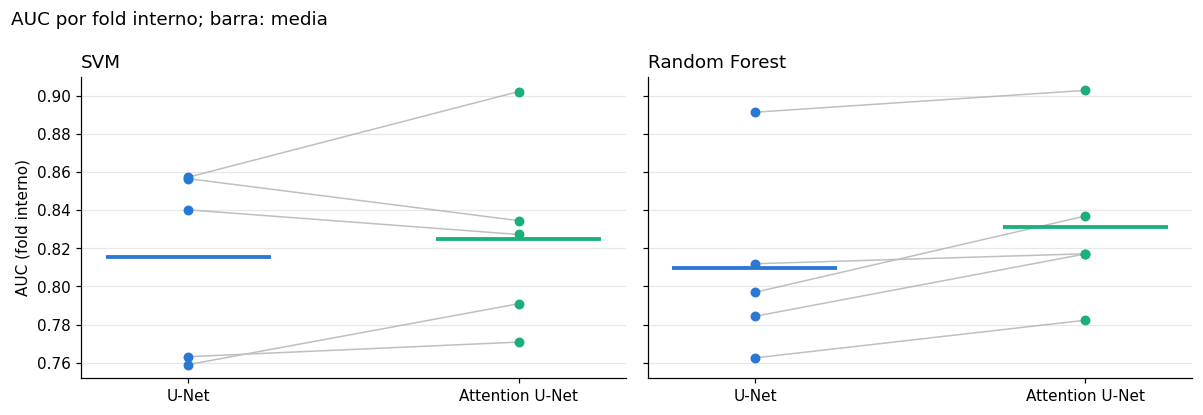

In [9]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5.5 * len(MODELS), 3.8), sharey=True, squeeze=False)
for ax, model_name in zip(axes[0], MODELS):
    auc = cv_metrics[cv_metrics["model"] == model_name].pivot(index="fold", columns="method", values="auc")[METHODS]
    x = np.arange(len(METHODS))
    for _, row in auc.iterrows():
        ax.plot(x, row.to_numpy(), color="0.75", lw=1, zorder=1)
    for i, method in enumerate(METHODS):
        ax.scatter(np.full(len(auc), i), auc[method], color=METHOD_COLORS.get(method), s=30, zorder=2)
        ax.hlines(auc[method].mean(), i - 0.25, i + 0.25, color=METHOD_COLORS.get(method), lw=2.5, zorder=3)
    ax.set_xticks(x, [name(m) for m in METHODS])
    ax.set_title(name(model_name), loc="left"); ax.grid(axis="y", alpha=0.3)
axes[0, 0].set_ylabel("AUC (fold interno)")
fig.suptitle("AUC por fold interno; barra: media", x=0.01, ha="left")
fig.tight_layout()
plt.show()

## 7 · Evaluación en el conjunto de prueba

**A partir de aquí se usan las imágenes de prueba.** Los modelos ya están fijos. Si después de ver estos resultados se cambian los hiperparámetros, las características o el protocolo, el conjunto de prueba deja de ser independiente.

Cada métrica se reporta con su intervalo de confianza del 95 % por bootstrap. Se remuestrean **pacientes**, de modo que las radiografías de un paciente entran o salen juntas. El intervalo solo refleja la variación entre imágenes, no el azar del entrenamiento.

### 7.1 Resultados

In [10]:
def bootstrap_samples(patients) -> list:
    # Posiciones de cada remuestreo: las radiografías de un paciente entran o salen juntas
    rng = np.random.default_rng(SEED)
    groups = list(pd.Series(patients.to_numpy()).groupby(patients.to_numpy()).indices.values())
    return [np.concatenate([groups[i] for i in rng.integers(len(groups), size=len(groups))]) for _ in range(N_BOOTSTRAP)]


def bootstrap_metrics(df, samples) -> pd.DataFrame:
    # Métricas de cada remuestreo; se omiten los que quedan con una sola clase
    y, pred, score = df["tb"].to_numpy(), df["pred"].to_numpy(), df["score"].to_numpy()
    return pd.DataFrame([compute_metrics(y[i], pred[i], score[i]) for i in samples if 0 < y[i].sum() < len(i)])


def metric_rows(df, draws, **keys) -> list:
    point = compute_metrics(df["tb"].to_numpy(), df["pred"].to_numpy(), df["score"].to_numpy())
    rows = []
    for metric in METRICS:
        low, high = np.percentile(draws[metric], [2.5, 97.5])
        rows.append({**keys, "imagenes": len(df), "metric": metric, "value": point[metric], "ci_low": low, "ci_high": high})
    return rows


def metrics_table(rows: pd.DataFrame, index: list) -> pd.DataFrame:
    # Una fila por grupo y una columna por métrica: valor [IC 95 %]
    text = (rows["value"].map("{:.3f}".format) + " [" + rows["ci_low"].map("{:.3f}".format)
            + ", " + rows["ci_high"].map("{:.3f}".format) + "]")
    table = rows.assign(text=text).set_index([*index, "metric"])["text"].unstack("metric")[METRICS]
    return table.loc[pd.MultiIndex.from_frame(rows[index].drop_duplicates())].rename(index=name)


predictions = pd.concat([
    test.assign(model=model_name, method=method, score=positive_score(search, X_test[method]),
                pred=search.predict(X_test[method]))
    for (model_name, method), search in searches.items()
], ignore_index=True)

samples = bootstrap_samples(test["patient_id"])
draws, rows = {}, []
for (model_name, method), group in predictions.groupby(["model", "method"], sort=False):
    draws[model_name, method] = bootstrap_metrics(group, samples)
    rows += metric_rows(group, draws[model_name, method], model=model_name, method=method, scope="todas")
    for source, subgroup in group.groupby("source", sort=False):
        source_draws = bootstrap_metrics(subgroup, bootstrap_samples(subgroup["patient_id"]))
        rows += metric_rows(subgroup, source_draws, model=model_name, method=method, scope=source)
test_metrics = pd.DataFrame(rows)

display(metrics_table(test_metrics[test_metrics["scope"] == "todas"], ["model", "method"]))

metric                                          auc          sensibilidad  \
model         method                                                        
SVM           U-Net            0.739 [0.651, 0.820]  0.739 [0.634, 0.841]   
              Attention U-Net  0.769 [0.686, 0.845]  0.754 [0.645, 0.849]   
Random Forest U-Net            0.748 [0.665, 0.827]  0.652 [0.539, 0.761]   
              Attention U-Net  0.732 [0.645, 0.813]  0.609 [0.493, 0.721]   

metric                                especificidad  exactitud_balanceada  \
model         method                                                        
SVM           U-Net            0.736 [0.630, 0.833]  0.738 [0.663, 0.809]   
              Attention U-Net  0.736 [0.632, 0.833]  0.745 [0.671, 0.815]   
Random Forest U-Net            0.708 [0.600, 0.811]  0.680 [0.602, 0.757]   
              Attention U-Net  0.722 [0.618, 0.823]  0.665 [0.586, 0.742]   

metric                                           f1  
model         method                                 
SVM           U-Net            0.734 [0.645, 0.810]  
              Attention U-Net  0.743 [0.655, 0.819]  
Random Forest U-Net            0.667 [0.567, 0.752]  
              Attention U-Net  0.641 [0.541, 0.731]

### 7.2 Curvas ROC

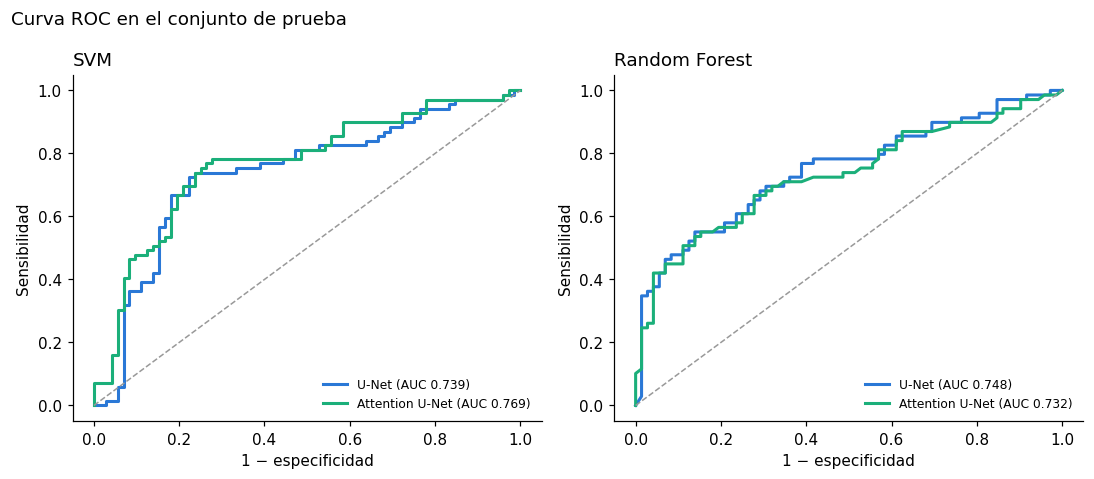

In [11]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.4), squeeze=False)
for ax, model_name in zip(axes[0], MODELS):
    for method in METHODS:
        group = predictions[(predictions["model"] == model_name) & (predictions["method"] == method)]
        fpr, tpr, _ = roc_curve(group["tb"], group["score"])
        ax.plot(fpr, tpr, lw=2, color=METHOD_COLORS.get(method),
                label=f"{name(method)} (AUC {roc_auc_score(group['tb'], group['score']):.3f})")
    ax.plot([0, 1], [0, 1], ls="--", color="0.6", lw=1)
    ax.set_xlabel("1 − especificidad"); ax.set_ylabel("Sensibilidad")
    ax.set_title(name(model_name), loc="left"); ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.suptitle("Curva ROC en el conjunto de prueba", x=0.01, ha="left")
fig.tight_layout()
plt.show()

### 7.3 Desempeño por fuente

Las fuentes difieren en adquisición y en la convención de anotación de las máscaras (`01b`, sección 8). Si el desempeño cae en una de ellas, el modelo puede estar aprendiendo la fuente y no la enfermedad.

Prueba tiene 27 imágenes de Montgomery (11 TB y 16 normales) y 114 de Shenzhen (58 TB y 56 normales). Con tan pocas imágenes, el intervalo de Montgomery es amplio y un valor aislado no permite concluir.

In [12]:
by_source = test_metrics[test_metrics["scope"] != "todas"]
display(metrics_table(by_source, ["model", "method", "scope"]))

metric                                                     auc  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.776 [0.679, 0.863]   
                              Montgomery  0.585 [0.369, 0.807]   
              Attention U-Net Shenzhen    0.774 [0.683, 0.859]   
                              Montgomery  0.739 [0.533, 0.914]   
Random Forest U-Net           Shenzhen    0.778 [0.689, 0.858]   
                              Montgomery  0.562 [0.311, 0.812]   
              Attention U-Net Shenzhen    0.749 [0.656, 0.835]   
                              Montgomery  0.648 [0.420, 0.869]   

metric                                            sensibilidad  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.793 [0.679, 0.892]   
                              Montgomery  0.455 [0.154, 0.765]   
              Attention U-Net Shenzhen    0.793 [0.683, 0.892]   
                              Montgomery  0.545 [0.231, 0.857]   
Random Forest U-Net           Shenzhen    0.707 [0.585, 0.825]   
                              Montgomery  0.364 [0.091, 0.667]   
              Attention U-Net Shenzhen    0.638 [0.511, 0.763]   
                              Montgomery  0.455 [0.154, 0.769]   

metric                                           especificidad  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.750 [0.632, 0.857]   
                              Montgomery  0.688 [0.462, 0.909]   
              Attention U-Net Shenzhen    0.714 [0.593, 0.827]   
                              Montgomery  0.812 [0.600, 1.000]   
Random Forest U-Net           Shenzhen    0.696 [0.574, 0.811]   
                              Montgomery  0.750 [0.529, 0.941]   
              Attention U-Net Shenzhen    0.714 [0.593, 0.825]   
                              Montgomery  0.750 [0.529, 0.941]   

metric                                    exactitud_balanceada  \
model         method          scope                              
SVM           U-Net           Shenzhen    0.772 [0.690, 0.843]   
                              Montgomery  0.571 [0.378, 0.770]   
              Attention U-Net Shenzhen    0.754 [0.673, 0.829]   
                              Montgomery  0.679 [0.493, 0.861]   
Random Forest U-Net           Shenzhen    0.702 [0.614, 0.783]   
                              Montgomery  0.557 [0.378, 0.741]   
              Attention U-Net Shenzhen    0.676 [0.588, 0.760]   
                              Montgomery  0.602 [0.418, 0.784]   

metric                                                      f1  
model         method          scope                             
SVM           U-Net           Shenzhen    0.780 [0.686, 0.855]  
                              Montgomery  0.476 [0.182, 0.720]  
              Attention U-Net Shenzhen    0.767 [0.673, 0.844]  
                              Montgomery  0.600 [0.286, 0.828]  
Random Forest U-Net           Shenzhen    0.707 [0.606, 0.796]  
                              Montgomery  0.421 [0.118, 0.667]  
              Attention U-Net Shenzhen    0.667 [0.558, 0.763]  
                              Montgomery  0.500 [0.200, 0.737]

## 8 · Comparación entre técnicas de segmentación

Esta es la pregunta del proyecto. Como todas las técnicas se evalúan sobre las mismas imágenes de prueba, la comparación es **pareada**: en cada remuestreo se resta la métrica de la técnica de referencia (la primera de `METHODS`) a la de cada técnica.

Se usa el mismo criterio de `02_segmentacion`: **si el intervalo de confianza del 95 % incluye el cero, la diferencia no es concluyente.**

La segunda tabla cuenta las imágenes de prueba cuya predicción cambia al cambiar de técnica. Mide el efecto de la segmentación aunque la métrica global no se mueva, porque un cambio de un caso a otro se puede compensar.

In [13]:
REFERENCE = METHODS[0]
point = test_metrics[test_metrics["scope"] == "todas"].set_index(["model", "method", "metric"])["value"]
rows, changes = [], []
for model_name in MODELS:
    selected = predictions[predictions["model"] == model_name]
    reference_pred = selected.loc[selected["method"] == REFERENCE, "pred"].to_numpy()
    for method in METHODS[1:]:
        differences = draws[model_name, method] - draws[model_name, REFERENCE]
        for metric in METRICS:
            low, high = np.percentile(differences[metric], [2.5, 97.5])
            rows.append({"model": model_name, "method": method, "metric": metric,
                         "reference": point[model_name, REFERENCE, metric], "value": point[model_name, method, metric],
                         "difference": point[model_name, method, metric] - point[model_name, REFERENCE, metric],
                         "ci_low": low, "ci_high": high, "conclusive": not low <= 0 <= high})
        changed = selected.loc[selected["method"] == method, "pred"].to_numpy() != reference_pred
        changes.append({"modelo": name(model_name), "técnica": name(method),
                        "predicciones que cambian": f"{changed.sum()} de {len(changed)}"})
comparison = pd.DataFrame(rows)

if comparison.empty:
    print("Se necesita más de una técnica en METHODS para comparar.")
else:
    print(f"Referencia: {name(REFERENCE)}")
    display(comparison.assign(
        difference=comparison["difference"].map("{:+.4f}".format),
        ic_95=comparison["ci_low"].map("[{:+.4f}, ".format) + comparison["ci_high"].map("{:+.4f}]".format),
    ).drop(columns=["ci_low", "ci_high"]).set_index(["model", "method", "metric"]).round(4).rename(index=name))
    display(pd.DataFrame(changes).set_index(["modelo", "técnica"]))

Referencia: U-Net


reference   value  \
model         method          metric                                    
SVM           Attention U-Net auc                      0.7387  0.7685   
                              sensibilidad             0.7391  0.7536   
                              especificidad            0.7361  0.7361   
                              exactitud_balanceada     0.7376  0.7449   
                              f1                       0.7338  0.7429   
Random Forest Attention U-Net auc                      0.7480  0.7316   
                              sensibilidad             0.6522  0.6087   
                              especificidad            0.7083  0.7222   
                              exactitud_balanceada     0.6803  0.6655   
                              f1                       0.6667  0.6412   

                                                   difference  conclusive  \
model         method          metric                                        
SVM           Attention U-Net auc                     +0.0298       False   
                              sensibilidad            +0.0145       False   
                              especificidad           +0.0000       False   
                              exactitud_balanceada    +0.0072       False   
                              f1                      +0.0090       False   
Random Forest Attention U-Net auc                     -0.0164       False   
                              sensibilidad            -0.0435       False   
                              especificidad           +0.0139       False   
                              exactitud_balanceada    -0.0148       False   
                              f1                      -0.0254       False   

                                                                 ic_95  
model         method          metric                                    
SVM           Attention U-Net auc                   [-0.0151, +0.0713]  
                              sensibilidad          [-0.0520, +0.0781]  
                              especificidad         [-0.0781, +0.0759]  
                              exactitud_balanceada  [-0.0429, +0.0568]  
                              f1                    [-0.0414, +0.0579]  
Random Forest Attention U-Net auc                   [-0.0539, +0.0201]  
                              sensibilidad          [-0.1096, +0.0156]  
                              especificidad         [-0.0694, +0.0938]  
                              exactitud_balanceada  [-0.0674, +0.0352]  
                              f1                    [-0.0813, +0.0253]

,,predicciones que cambian
modelo,técnica,
SVM,Attention U-Net,13 de 141
Random Forest,Attention U-Net,14 de 141


## 9 · Importancia de características

Importancia de Random Forest (reducción media de impureza), calculada con el modelo entrenado en desarrollo. Responde una pregunta complementaria: **¿la técnica de segmentación cambia qué características usa el modelo?**, aunque la AUC no cambie.

Las características correlacionadas se reparten la importancia, así que se lee **por grupo** (`03_radiomica`, secciones 2 y 3). `Energy` merece atención aparte: depende sobre todo del tamaño de la máscara (ρ = 0,86 con el área), así que es la característica que más directamente recibe el efecto de la segmentación.

method                     U-Net  Attention U-Net
model         group                              
Random Forest Posición     0.130            0.118
              Dispersión   0.333            0.325
              Complejidad  0.080            0.080
              Magnitud     0.104            0.122
              Sin grupo    0.353            0.354

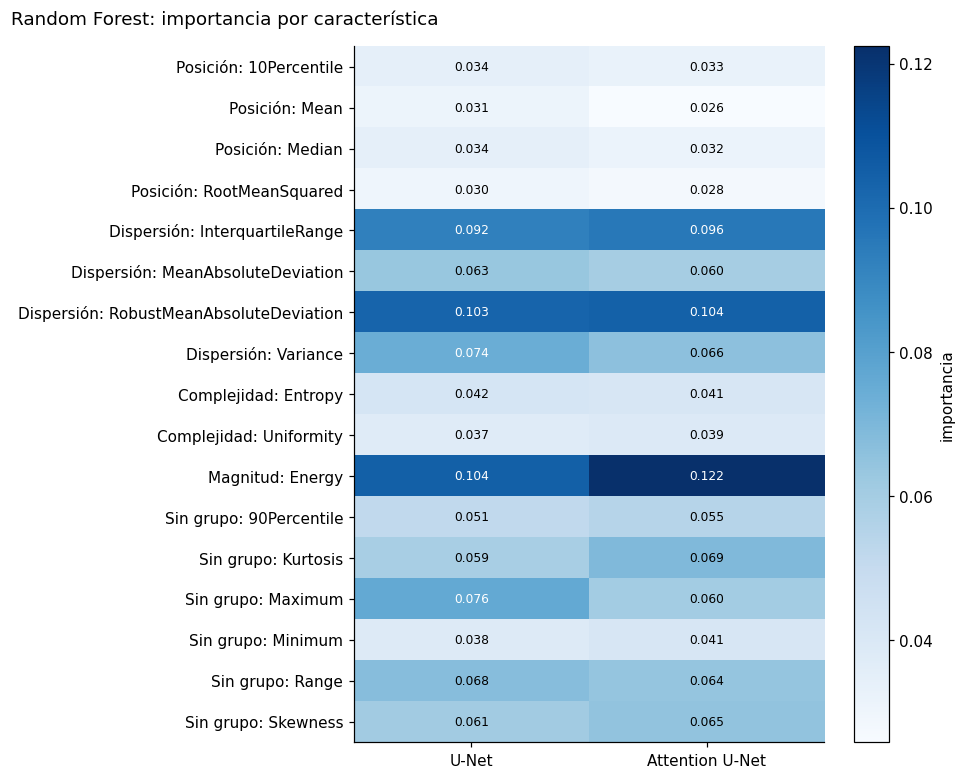

In [30]:
FEATURE_GROUPS = {
    "Posición": ["10Percentile", "Mean", "Median", "RootMeanSquared"],
    "Dispersión": ["InterquartileRange", "MeanAbsoluteDeviation", "RobustMeanAbsoluteDeviation", "Variance"],
    "Complejidad": ["Entropy", "Uniformity"],
    "Magnitud": ["Energy"],
}
NO_GROUP = "Sin grupo"
GROUP_OF = {feature: group for group, members in FEATURE_GROUPS.items() for feature in members}

importances = pd.DataFrame([
    {"model": model_name, "method": method, "feature": feature, "group": GROUP_OF.get(feature, NO_GROUP), "importance": value}
    for (model_name, method), search in searches.items() if hasattr(search.best_estimator_[-1], "feature_importances_")
    for feature, value in zip(FEATURES, search.best_estimator_[-1].feature_importances_)
])

if importances.empty:
    print("Ningún modelo de MODELS expone feature_importances_.")
else:
    group_order = [*FEATURE_GROUPS, NO_GROUP]
    by_group = importances.pivot_table(index=["model", "group"], columns="method", values="importance", aggfunc="sum")
    display(by_group[METHODS].reindex(group_order, level="group").round(3).rename(index=name, columns=name))

    order = sorted(FEATURES, key=lambda f: (group_order.index(GROUP_OF.get(f, NO_GROUP)), f))
    for model_name, group in importances.groupby("model", sort=False):
        data = group.pivot(index="feature", columns="method", values="importance").loc[order, METHODS]
        fig, ax = plt.subplots(figsize=(1.6 * len(METHODS) + 5.5, 0.34 * len(order) + 1.4))
        image = ax.imshow(data.to_numpy(), cmap="Blues", aspect="auto")
        ax.set_xticks(range(len(METHODS)), [name(m) for m in METHODS])
        ax.set_yticks(range(len(order)), [f"{GROUP_OF.get(f, NO_GROUP)}: {f}" for f in order])
        for (i, j), v in np.ndenumerate(data.to_numpy()):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if v > data.to_numpy().max() * 0.6 else "black")
        fig.colorbar(image, ax=ax, label="importancia")
        fig.suptitle(f"{name(model_name)}: importancia por característica", x=0.01, ha="left")
        fig.tight_layout()
        plt.show()

## 10 · Guardado

Se guardan seis archivos en `results/classification/<dataset>/<familias>/`. La carpeta incluye las familias para que dos experimentos no se sobrescriban.

| Archivo | Contenido |
|---|---|
| `cv_metrics.csv` | AUC de cada técnica × modelo × fold interno |
| `best_params.csv` | Hiperparámetros elegidos y AUC interna |
| `test_predictions.csv` | Puntaje y predicción de cada imagen de prueba |
| `test_metrics.csv` | Métricas de prueba con intervalo de confianza, globales y por fuente |
| `test_comparison.csv` | Diferencias frente a la técnica de referencia |
| `importances.csv` | Importancia de cada característica (modelos que la exponen) |

In [31]:
CLF_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
outputs = {"cv_metrics.csv": cv_metrics, "best_params.csv": best_params, "test_predictions.csv": predictions,
           "test_metrics.csv": test_metrics, "test_comparison.csv": comparison, "importances.csv": importances}
for file_name, df in outputs.items():
    df.to_csv(CLF_RESULTS_DIR / file_name, index=False)
print(f"Guardado en {CLF_RESULTS_DIR.relative_to(ROOT)}: {', '.join(outputs)}")

Guardado en results/classification/montgomery_shenzhen/firstorder: cv_metrics.csv, best_params.csv, test_predictions.csv, test_metrics.csv, test_comparison.csv, importances.csv
